# [기초-실습] 통계 101×데이터 분석: (4장) 추론통계~신뢰구간

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비 — 한글 폰트 설치 및 라이브러리 불러오기

In [ ]:
# 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Sudo is disabled on this machine. To enable it, go to the ]8;;ms-settings:developers\Developer Settings page]8;;\ in the Settings app
Sudo is disabled on this machine. To enable it, go to the ]8;;ms-settings:developers\Developer Settings page]8;;\ in the Settings app
'rm' is not recognized as an internal or external command,
operable program or batch file.


In [4]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'Malgun Gothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

# 문제 1. 표본조사 체험하기

**📘 문제**

- 온라인 쇼핑몰은 전체 고객 수가 너무 많아, 모든 고객을 조사하기 어렵습니다.

- 그래서 무작위로 고객 30명을 뽑아 평균 만족도를 계산하고 이를 전체 만족도의 추정값으로 사용하려 합니다.

- 이번 실습에서는 직접 표본을 뽑고, 표본 평균을 구해보며,
  **“표본마다 결과가 달라질 수 있다”**는 추론 통계의 핵심 개념을 체험해봅니다.

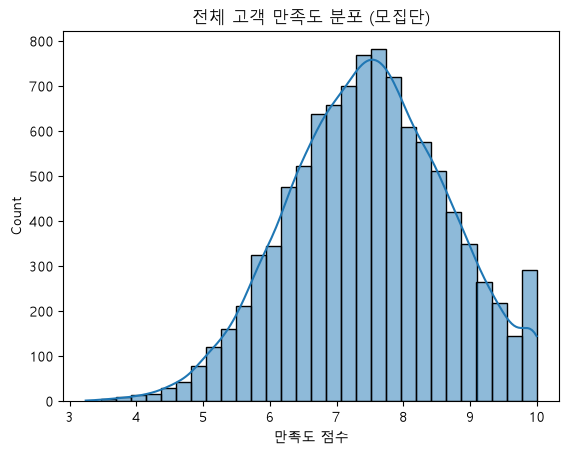

In [5]:
# 모집단 생성 (전체 고객 만족도 10,000명)
np.random.seed(2025)
population = np.random.normal(loc=7.5, scale=1.2, size=10000)
population = np.clip(population, 1, 10)  # 1점 ~ 10점 사이로 제한
df_pop = pd.DataFrame({'score': population})

# 전체 모집단 시각화
sns.histplot(df_pop['score'], bins=30, kde=True)
plt.title("전체 고객 만족도 분포 (모집단)")
plt.xlabel("만족도 점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 표본을 무작위로 여러 번 뽑아 보고, 표본 평균이 어떻게 변하는지 확인해봅시다.

- 히스토그램을 그리고, 표본 평균의 분포 형태를 관찰해봅시다.

In [6]:
# [문제 1] Q1. 모집단에서 무작위로 30명을 뽑아 표본 평균을 구해봅시다.
# 여기에 코드를 작성해주세요.

#무작위 30명 표본 추출
sample = df_pop.sample(n=30, random_state=42)

#표본 평균 구하기
sample_mean = sample["score"].mean()

print(f"표본평균: {sample_mean:.2f}")
print(f"모집단 평균: {df_pop["score"].mean():.2f}")
print(f"표본오차: {sample_mean - df_pop["score"].mean():.2f}")

표본평균: 7.51
모집단 평균: 7.48
표본오차: 0.03


In [7]:
# [문제 1] Q2. 이 과정을 500번 반복하고, 표본 평균을 리스트에 저장합니다.
# 여기에 코드를 작성해주세요.

#표본평균을 담을 빈 리스트
sample_means = []

for i in range(500):
    sample = df_pop.sample(n=30)
    sample_means.append(sample['score'].mean())


print(f"저장된 표본평균 개수: {len(sample_means)}")
print(f"처음 5개: {[round(m, 2) for m in sample_means[:5]]}")





저장된 표본평균 개수: 500
처음 5개: [np.float64(7.2), np.float64(7.22), np.float64(7.58), np.float64(7.6), np.float64(7.26)]


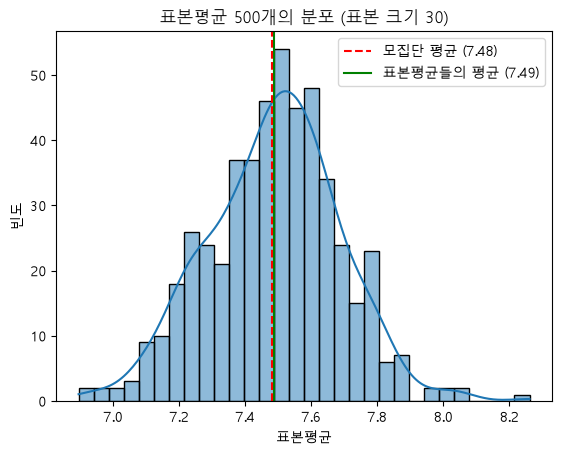

In [10]:
# [문제 1] Q3. 표본 평균들의 분포를 히스토그램으로 그려봅시다. 평균선도 함께 표시해 봅시다.
# 여기에 코드를 작성해주세요.

pop_mean = df_pop['score'].mean()        # 모집단 평균
means_mean = np.mean(sample_means)       # 표본평균 500개의 평균

sns.histplot(sample_means, bins=30, kde=True)
plt.axvline(pop_mean, color='red', linestyle='--', label=f'모집단 평균 ({pop_mean:.2f})')
plt.axvline(means_mean, color='green', linestyle='-', label=f'표본평균들의 평균 ({means_mean:.2f})')

plt.title("표본평균 500개의 분포 (표본 크기 30)")
plt.xlabel("표본평균")
plt.ylabel("빈도")
plt.legend()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 평균들은 어떤 값 주변에 많이 분포해 있나요? 이 값은 전체 모집단 평균과 얼마나 비슷한가요?

> 표본 평균들은 7.5 주변에 많이 분포해 있다. 예를 들어 7.2, 7.22, 7.58과 같이. 모집단 평균이 7.48로 거의 비슷하다.

- 표본을 1번 뽑았을 때와 500번을 반복해서 뽑았을 때, 표본 평균의 분포나 신뢰성에는 어떤 차이가 있나요

> 표본을 1번만 뽑으면 해당 표본의 평균만 알 수 있어 모집단의 특성을 정확하게 파악하기 어려움
> 500번을 반복하여 표본 평균을 구하면 표본 평균들의 분포 확인 가능. 모집단 평균 주변에 얼마나 모이는지 파악. 반복 횟수가 많아질수록 표본 평균의 분포를 더 안정적으로 관찰 가능

- 친구가 다른 표본을 뽑았다면 같은 평균이 나왔을까요? 비슷한 결과가 나왔더라도 완전히 같지 않았다면, 그 이유는 무엇일까요?

> 완전히 같은 평균이 나오지 않을 가능성이 더 높다. 무작위 표본 추출 과정에서 선택되는 고객이 달라지기 때문이다. 이를 표본 추출에 따른 변동이라고 하며, 서로 다른 표본에서도 평균은 대체로 모집단 평균 주변에 분포한다.

- 표본 평균들의 분포는 어떤 모양인가요? 종 모양의 정규분포처럼 보이나요? 그렇다면 왜 그렇게 되는 걸까요?
> 7.5를 중심으로 한 종 모양의 정규분포로 보인다. 이는 중심극한정리에 의해 모집단의 분포와 관계없이 표본 크기가 충분히 크면 표본 평균의 분포가 정규분포에 가까워지기 때문이다. 

In [ ]:
# [문제 1] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

# 문제 2. 중심극한정리

**📘 문제**

- 현실에서는 모집단의 분포가 정규분포가 아닐 수도 있습니다.

- 예를 들어, 일부 고객은 매우 높은 점수를 주고, 대부분은 낮은 점수를 주는 만족도 분포가 있을 수 있죠. (예: 지수분포)

- 이처럼 원래 분포가 비정규분포여도,
  표본을 여러 번 뽑아 평균을 계산하면, 그 평균들의 분포는 정규분포에 가까워진다는 것을
  **중심극한정리(Central Limit Theorem)**라고 합니다.

- 이번 실습에서는 다양한 크기의 표본을 뽑아 평균을 계산하고,
  그 평균들의 분포가 어떻게 변하는지를 직접 실험해 봅니다.

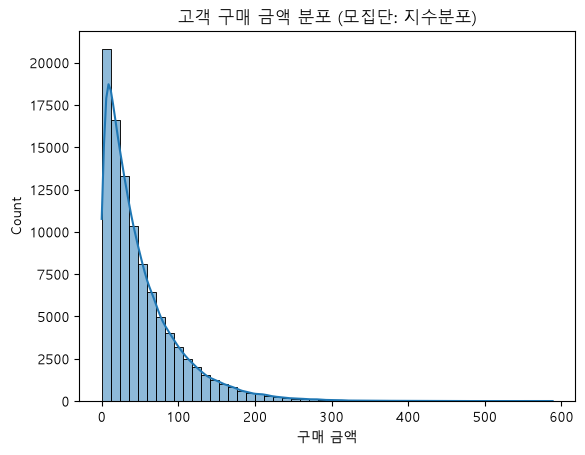

In [12]:
# 지수분포를 따르는 모집단 생성
np.random.seed(2025)
population = np.random.exponential(scale=50, size=100000)  # 평균 50, 비대칭 분포

# 모집단 시각화
sns.histplot(population, bins=50, kde=True)
plt.title("고객 구매 금액 분포 (모집단: 지수분포)")
plt.xlabel("구매 금액")
plt.show()

**📌 아래를 수행해 보세요:**

- 비대칭적인 모집단(지수분포)에서 무작위로 표본을 추출해 평균을 구해봅시다.

- 표본 크기를 바꿔가며, 표본 평균들의 분포가 어떻게 변화하는지 확인해봅시다.

- 히스토그램을 그리고, 분포의 모양을 관찰해봅시다.

- 표본 크기가 커질수록 표본 평균 분포의 모양과 **퍼진 정도(분산)**가 어떻게 변하는지 관찰해봅시다.

In [13]:
# [문제 2] Q1. 모집단에서 표본을 1000번 뽑고, 각 표본의 평균을 구해봅시다.
# 표본 크기 = 5일 때

# 여기에 코드를 작성해주세요.

sample_means_5 = []

for i in range(1000):
    sample = np.random.choice(population, size=5, replace=False)
    sample_means_5.append(sample.mean())

print(f"저장된 표본평균 개수: {len(sample_means_5)}")
print(f"모집단 평균: {population.mean():.2f}")
print(f"표본평균들의 평균: {np.mean(sample_means_5):.2f}")


저장된 표본평균 개수: 1000
모집단 평균: 50.23
표본평균들의 평균: 49.41


In [15]:
# [문제 2] Q2. 위 과정을 표본 크기 30, 100일 때도 반복해봅시다.
# sample_size = 30, 100

# 여기에 코드를 작성해주세요.

sample_means_30 = []
sample_means_100 = []

for i in range(1000):
    sample_means_30.append(np.random.choice(population, size=30, replace=False).mean())
    sample_means_100.append(np.random.choice(population, size=100, replace=False).mean())

# 결과 비교
for n, means in [(5, sample_means_5), (30, sample_means_30), (100, sample_means_100)]:
    print(f"표본 크기 {n:>3}: 표본평균들의 평균 = {np.mean(means):.2f}, "
          f"표준편차 = {np.std(means):.2f}")

표본 크기   5: 표본평균들의 평균 = 49.41, 표준편차 = 22.43
표본 크기  30: 표본평균들의 평균 = 50.66, 표준편차 = 9.43
표본 크기 100: 표본평균들의 평균 = 50.38, 표준편차 = 5.09


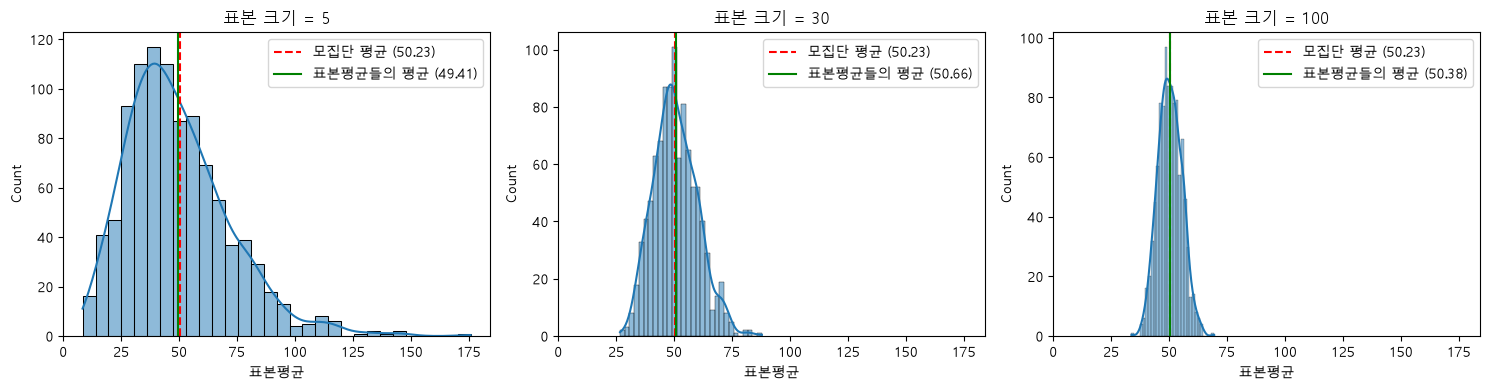

In [16]:
# [문제 2] Q3. 각 표본 크기별로 표본 평균들의 분포를 히스토그램으로 그려봅시다.
# 평균선을 함께 표시해 봅시다.

# 여기에 코드를 작성해주세요.

pop_mean = population.mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)

for ax, n, means in zip(axes, [5, 30, 100], [sample_means_5, sample_means_30, sample_means_100]):
    sns.histplot(means, bins=30, kde=True, ax=ax)
    ax.axvline(pop_mean, color='red', linestyle='--', label=f'모집단 평균 ({pop_mean:.2f})')
    ax.axvline(np.mean(means), color='green', linestyle='-', label=f'표본평균들의 평균 ({np.mean(means):.2f})')
    ax.set_title(f"표본 크기 = {n}")
    ax.set_xlabel("표본평균")
    ax.legend()

plt.tight_layout()
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 크기가 작을 때 (예: 5), 평균들의 분포는 어떤 모양인가요?
> 오른쪽으로 치우친 비대칭적인 형태. : 원래 모집단이 지수분포를 따르기 때문에 표본 평균에도 비대칭성이 남아 있기 때문이다.

- 표본 크기가 커질수록 평균 분포의 모양은 어떤 변화를 보이나요?
> 표본의 크기가 커질 수록 종 모양의 정규분포에 가까워진다. 

- 원래 모집단은 비대칭이었는데, 왜 평균들의 분포는 정규분포처럼 바뀌었을까요?
> 중심극한정리에 따르면 모집단이 비정규분포이더라도 표본 크기가 충분히 크면 표본 평균들의 분포는 정규분포에 가까워 진다. 위의 결과도 표본 크기가 커지면서 원래 모집단의 비대칭성이 줄어들고 정규분표에 가까워지는 모습을 관찰할 수 있다.

- 이 실험을 통해 중심극한정리를 어떻게 이해하게 되었나요?
> 원래 모집단의 모양에 상관없이 표본 크기가 충분히 크면 표본평균의 분포는 정규분포에 가까워진다는 것을 눈으로 확인할 수 있었다. 

- 표본 크기에 따라 **분포의 넓이(흩어짐)**는 어떻게 달라지나요?
> 표본의 크기가 커질수록 분포의 넓이는 좁아지고 흩어짐이 줄어든다. 표본 크기가 커지면서 개별 관측값의 영향이 줄어들어 표본 평균이 모집단 평균 주변에 더 안정적으로 모이기 때문
> 표본 크기에 따라 상쇄되는 것이 많아지면서 분포의 넓이 즉 흩어짐이 줄어든다.

In [ ]:
# [문제 2]데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

# 문제 3. 표준오차

**📘 문제**

- 앞선 실습에서 우리는 **표본 크기(n)가 커질수록 표본 평균들의 분포가 더 좁아진다**는 것을 확인했습니다.
- 이처럼 표본 평균들이 얼마나 흩어져 있는지(분포의 퍼진 정도)를 나타내는 값을 **표준오차(Standard Error, SE)**라고 부릅니다.
- 표준오차는 **표본 평균들의 표준편차**와 같은 의미이며, 이는 우리가 뽑은 표본 평균이 실제 모평균과 평균적으로 얼마나 떨어져 있을지를 나타내는 **'예상 오차의 크기'**입니다.

- 통계학적으로 이 표준오차는 **`SE = σ / √n`** (모집단 표준편차 / 표본 크기의 제곱근) 이라는 공식으로 계산할 수 있습니다.
- 이 공식은 **표본 크기(n)가 커질수록 표준오차(SE)가 작아진다**는 것을 명확히 보여줍니다.

- 이번 실습에서는 여러 크기의 표본을 뽑아, 시뮬레이션을 통해 얻은 **표본 평균들의 표준편차(실험값)**가 공식으로 계산한 **표준오차(이론값)**와 얼마나 일치하는지 직접 확인해봅니다.

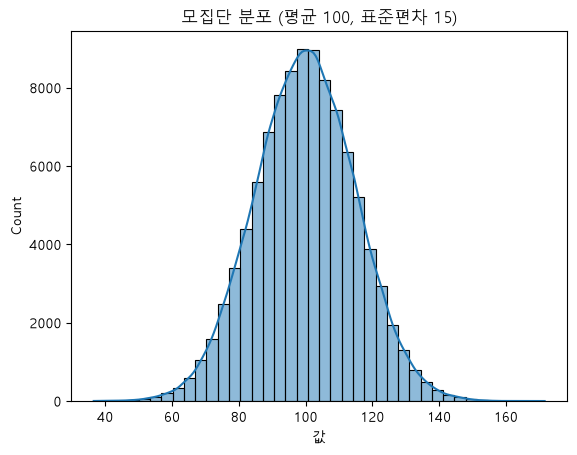

In [17]:
# 모집단 생성 (평균 100, 표준편차 15)
np.random.seed(2025)
population = np.random.normal(loc=100, scale=15, size=100000)

# 모집단 시각화
sns.histplot(population, bins=40, kde=True)
plt.title("모집단 분포 (평균 100, 표준편차 15)")
plt.xlabel("값")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단에서 여러 크기의 표본(10, 30, 100, 500)을 각각 1000번 뽑고, 그 평균들을 구한 뒤, **표본 평균들의 표준편차(=실험적 표준오차)**를 계산해봅시다.

- 이 결과를 이론적인 표준오차 공식과 비교하는 표를 만들고, 시각화해봅시다.

In [19]:
# [문제 3] Q1. 표본 크기 10, 30, 100, 500에 대해 각각 1000번 표본을 뽑고, 평균을 구해봅시다.
# 각 표본 평균 분포의 표준편차를 계산해봅시다.
# 결과를 리스트에 저장하고, 표로 정리해봅시다.

# 여기에 코드를 작성해주세요.

sample_sizes = [10, 30, 100, 500]
mean_list = []   # 표본 크기별 '표본평균들의 평균'
std_list = []    # 표본 크기별 '표본평균 분포의 표준편차'

for n in sample_sizes:
    means = []
    for i in range(1000):
        sample = np.random.choice(population, size=n, replace=False)
        means.append(sample.mean())
    mean_list.append(np.mean(means))
    std_list.append(np.std(means))

# 표로 정리
result_df = pd.DataFrame({
    '표본 크기': sample_sizes,
    '표본평균들의 평균': mean_list,
    '표본평균 분포의 표준편차': std_list
})
result_df

,표본 크기,표본평균들의 평균,표본평균 분포의 표준편차
0,10,99.768862,4.817181
1,30,99.834604,2.755615
2,100,99.921467,1.593339
3,500,99.961331,0.671665


In [20]:
# [문제 3] Q2. 이론적인 표준오차와 비교해봅시다.
# [공식] 표준오차(SE) = 모집단 표준편차 / √표본크기

# 여기에 코드를 작성해주세요.

pop_std = population.std()   # 모집단 표준편차 (약 15)

result_df['이론적 표준오차'] = [pop_std / np.sqrt(n) for n in sample_sizes]
result_df['차이'] = result_df['표본평균 분포의 표준편차'] - result_df['이론적 표준오차']

result_df.round(3)

,표본 크기,표본평균들의 평균,표본평균 분포의 표준편차,이론적 표준오차,차이
0,10,99.769,4.817,4.754,0.063
1,30,99.835,2.756,2.745,0.011
2,100,99.921,1.593,1.503,0.090
3,500,99.961,0.672,0.672,-0.001


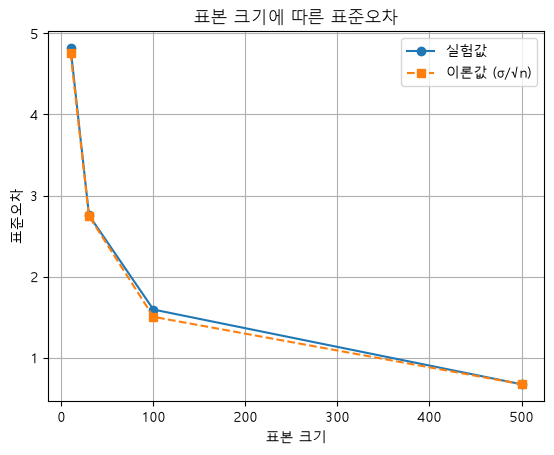

In [21]:
# [문제 3] Q3. 실험값과 이론값을 시각화해봅시다.
# 표본 크기를 x축, 표준오차를 y축으로 한 꺾은선 그래프를 그려봅시다.

# 여기에 코드를 작성해주세요.

plt.plot(result_df['표본 크기'], result_df['표본평균 분포의 표준편차'],
         marker='o', label='실험값')
plt.plot(result_df['표본 크기'], result_df['이론적 표준오차'],
         marker='s', linestyle='--', label='이론값 (σ/√n)')

plt.title("표본 크기에 따른 표준오차")
plt.xlabel("표본 크기")
plt.ylabel("표준오차")
plt.legend()
plt.grid(True)
plt.show()

**🧠 데이터를 어떻게 읽을까요?**

- 표본 크기가 작을수록, 표본 평균의 분포는 어떤 모양인가요? 넓게 퍼져 있나요?
> 표본 크기가 작을 수록 표본 평균들의 분포는 넓게 퍼져있다. 표본에 포함된 데이터가 적기 때문에 개별 관측값의 영향이 크고, 표본마다 평균이 달라질 가능성이 높기 때문

- 표본 크기가 커질수록, 평균 분포는 어떻게 변하나요?
> 표본 크기가 커질수록 표본 평균 분포는 점점 좁아진다. 표본 평균이 모집단 평균 주변에 더 집중되며, 평균을 추정하는 결과가 안정적으로 변함.

- 실험값과 이론값(공식 계산값)은 얼마나 비슷한가요?
> 거의 비슷하다. 약간의 차이는 표본을 무작위로 추출하는 과정에서 발생하는 변동 때문. 

- 왜 표본 크기가 커질수록 표준오차는 작아질까요?
> 표본 크기가 커지면 더 많은 데이터를 사용하여 평균을 계산하기 때문에 개별 관측값의 영향이 줄어든다. 따라서 평균이 모집단 평균 주변에 더 안정적으로 모인다. // 표준오차는 공식에 따라 표본 크기의 제곱근에 반비례!!

In [ ]:
# [문제 3] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

# 문제 4. 신뢰구간 계산과 해석

**📘 문제**

- 표본 평균은 모집단 평균을 추정하는 좋은 점 추정(Point Estimation) 값이지만, 표본오차 때문에 정확히 일치하지는 않습니다.

- 그래서 우리는 "모집단 평균이 아마 이 범위 안에 있을 것이다"라고 **구간으로 추정(Interval Estimation)**하는 것이 더 합리적입니다. 이때 사용하는 개념이 바로 **신뢰구간(Confidence Interval)**입니다.

- 신뢰구간은 표본평균 ± 오차범위 형태로 계산되며, 이 오차범위는 신뢰수준(예: 95%, 99%)과 표본오차에 의해 결정됩니다.

- 이번 실습에서는 **모집단 표준편차(σ)를 알 때(z-분포)**와 **모를 때(t-분포)**의 신뢰구간을 각각 계산해보고, 신뢰수준에 따라 구간의 폭이 어떻게 변하는지 확인해봅니다.

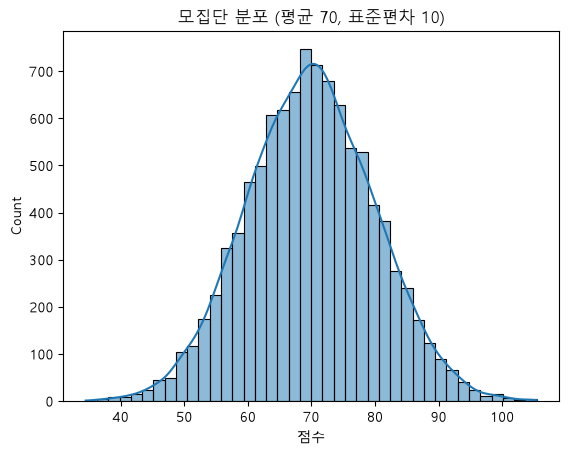

In [22]:
# 모집단 생성
np.random.seed(2025)
population = np.random.normal(loc=70, scale=10, size=10000)

# 모집단 시각화
sns.histplot(population, bins=40, kde=True)
plt.title("모집단 분포 (평균 70, 표준편차 10)")
plt.xlabel("점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단에서 30명을 무작위로 뽑아 평균, 표준편차, 표준오차를 계산해보세요.

- 95% 신뢰구간을 z-분포와 t-분포를 각각 사용해서 계산해보세요.

- 신뢰수준을 바꿨을 때(90%, 99%) 신뢰구간이 어떻게 변하는지 확인해보세요.

In [23]:
# [문제 4] Q1. 모집단에서 표본 30명을 무작위로 추출하고, 표본 평균과 표준편차를 구해봅시다.
# 표준오차도 함께 계산해보세요.

# 여기에 코드를 작성해주세요.

sample = np.random.choice(population, size=30, replace=False)

sample_mean = sample.mean()                    # 표본평균
sample_std = sample.std(ddof=1)                # 표본표준편차 (n-1로 나눔)
se = sample_std / np.sqrt(len(sample))         # 표준오차

print(f"표본 평균: {sample_mean:.2f}")
print(f"표본 표준편차: {sample_std:.2f}")
print(f"표준오차: {se:.2f}")

표본 평균: 67.60
표본 표준편차: 11.08
표준오차: 2.02


In [24]:
# [문제 4] Q2. 모집단의 표준편차를 알고 있다고 가정하고, z-분포를 사용하여 95% 신뢰구간을 계산해봅시다.

# 여기에 코드를 작성해주세요.

from scipy import stats

sigma = 10                          # 모집단 표준편차 (안다고 가정)
n = len(sample)                     # 표본 크기 30
se_z = sigma / np.sqrt(n)           # 표준오차

z = stats.norm.ppf(0.975)           # 95% 신뢰수준의 z값 (약 1.96)

lower = sample_mean - z * se_z
upper = sample_mean + z * se_z

print(f"z값: {z:.2f}")
print(f"95% 신뢰구간: ({lower:.2f}, {upper:.2f})")
print(f"모집단 평균: {population.mean():.2f}")

z값: 1.96
95% 신뢰구간: (64.03, 71.18)
모집단 평균: 69.90


In [25]:
# [문제 4] Q3. 모집단의 표준편차를 모른다고 가정하고, 표본 표준편차와 t-분포를 사용하여 95% 신뢰구간을 계산해봅시다.

# 여기에 코드를 작성해주세요.

n = len(sample)                         # 표본 크기 30
se_t = sample_std / np.sqrt(n)          # 표본표준편차로 구한 표준오차 (Q1의 se와 같음)

t = stats.t.ppf(0.975, df=n-1)          # 95% 신뢰수준의 t값 (자유도 29)

lower_t = sample_mean - t * se_t
upper_t = sample_mean + t * se_t

print(f"t값: {t:.3f}")
print(f"95% 신뢰구간 (t): ({lower_t:.2f}, {upper_t:.2f})")
print(f"95% 신뢰구간 (z): ({lower:.2f}, {upper:.2f})")
print(f"모집단 평균: {population.mean():.2f}")

t값: 2.045
95% 신뢰구간 (t): (63.47, 71.74)
95% 신뢰구간 (z): (64.03, 71.18)
모집단 평균: 69.90


In [26]:
# [문제 4] Q4. 신뢰수준을 90%, 99%로 바꿔가며 신뢰구간을 계산해보고, 그 폭을 비교해봅시다.

# 여기에 코드를 작성해주세요.

confidence_levels = [0.90, 0.95, 0.99]
results = []

for cl in confidence_levels:
    alpha = 1 - cl                                  # 바깥에 남는 비율 (예: 95%면 0.05)
    t_val = stats.t.ppf(1 - alpha/2, df=n-1)        # 해당 신뢰수준의 t값
    lower_cl = sample_mean - t_val * se_t
    upper_cl = sample_mean + t_val * se_t
    results.append([f"{int(cl*100)}%", t_val, lower_cl, upper_cl, upper_cl - lower_cl])

ci_df = pd.DataFrame(results, columns=['신뢰수준', 't값', '하한', '상한', '구간 폭'])
ci_df.round(2)

,신뢰수준,t값,하한,상한,구간 폭
0,90%,1.70,64.17,71.04,6.87
1,95%,2.05,63.47,71.74,8.27
2,99%,2.76,62.03,73.18,11.15


**🧠 데이터를 어떻게 읽을까요?**

- z-분포와 t-분포를 사용한 신뢰구간은 얼마나 차이가 있나요?
> z-분포와 t-분포를 사용한 신뢰구간은 대체로 비슷하지만 t-분포를 사용한 신뢰구간이 조금 더 넓게 나타난다. 모집단의 표준편차를 모르는 경우 표본 표준편차를 사용하기 때문에 불확실성이 더 크고, 이를 반영하기 위해 t-분포를 사용한다.

- 신뢰수준이 높아질수록 신뢰구간의 폭은 어떻게 변하나요? 왜 그럴까요?
> 신뢰수준이 높아질수록 신뢰구간의 폭이 더 넓어진다. 모집단 평균이 구간에 포함될 가능성을 더 높게 확보하려면 더 넓은 범위를 설정해야하기 때문이다. 
> 

- 신뢰구간이 넓다는 건 좋은 걸까요? 나쁜 걸까요?
> 신뢰구간이 넓으면 모집단 평균이 포함될 가능성을 높게 확보할 수 있지만, 추정의 정확성이 떨어지고 불확실성이 크다는 의미이다. 반대로 신뢰구간이 좁으면 모집단 평균을 더 정밀하게 추정할 수 있다. 따라서 신뢰수준과 구간 폭 사이의 균형이 중요하다.

- 이 데이터가 실제 고객 만족도라면, 신뢰구간 정보를 마케팅 전략에 어떻게 활용할 수 있을까요?
> 고객 만족도의 신뢰구간을 활용하면서 전체 고객의 만족도 수준을 추정하고, 만족도가 어느 정도 범위에 있을지 파악할 수 있다. 신뢰구간이 낮게 나타나면서 서비스 개선이 필요할 수도 있고 구간이 좁으면 고객 만족도에 대한 추정이 비교적 정밀하므로 마케팅 전략을 수집하는데 도움이 된다. 

In [ ]:
# [문제 4] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.

# 문제 5. 미니 프로젝트 - 고객 만족도 신뢰구간 추정

**📘 문제**

- 전체 고객 10,000명을 대상으로 만족도 조사를 하는 것은 시간과 비용이 많이 듭니다.
- 그래서 우리는 무작위로 일부 고객만 조사하여, 전체 고객의 평균 만족도를 추정하려 합니다.

- 이 프로젝트에서는 실제와 같은 상황을 가정하여, 표본을 뽑고 신뢰구간을 계산한 뒤, 이 결과를 바탕으로 마케팅 전략에 어떻게 활용할 수 있을지까지 생각해보는 실습을 진행합니다.

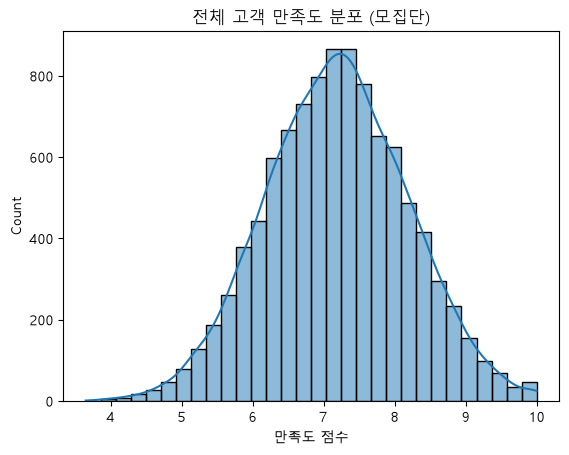

In [27]:
# 모집단 생성 (고객 만족도 10,000명)
np.random.seed(2025)
population = np.random.normal(loc=7.2, scale=1.0, size=10000)
population = np.clip(population, 1, 10)

# 모집단 시각화
sns.histplot(population, bins=30, kde=True)
plt.title("전체 고객 만족도 분포 (모집단)")
plt.xlabel("만족도 점수")
plt.show()

**📌 아래를 수행해 보세요:**

- 모집단을 생성하고, 거기서 표본을 40명 뽑아 평균을 계산해봅시다.

- 표본 평균과 표준편차를 바탕으로 95% 신뢰구간을 계산해봅시다.

- 히스토그램을 그리고 신뢰구간을 시각화해봅시다.

- 이 결과를 어떻게 해석하고, 마케팅 전략에 활용할 수 있을지 생각해봅시다.

In [28]:
# [문제 5] Q1. 모집단에서 표본 40명을 무작위로 추출하고, 표본 평균과 표준편차를 구해봅시다.
# 여기에 코드를 작성해주세요.

sample = np.random.choice(population, size=40, replace=False)

sample_mean = sample.mean()           # 표본평균
sample_std = sample.std(ddof=1)       # 표본표준편차 (n-1로 나눔)

print(f"표본 평균: {sample_mean:.2f}")
print(f"표본 표준편차: {sample_std:.2f}")

표본 평균: 7.14
표본 표준편차: 1.10


In [29]:
# [문제 5] Q2. 표준오차(SE)를 구하고, t-분포를 사용하여 95% 신뢰구간을 계산해봅시다.
# 여기에 코드를 작성해주세요.

n = len(sample)                          # 표본 크기 40
se = sample_std / np.sqrt(n)             # 표준오차

t = stats.t.ppf(0.975, df=n-1)           # 95% 신뢰수준의 t값 (자유도 39)

lower = sample_mean - t * se
upper = sample_mean + t * se

print(f"표준오차: {se:.3f}")
print(f"t값: {t:.3f}")
print(f"95% 신뢰구간: ({lower:.2f}, {upper:.2f})")

표준오차: 0.174
t값: 2.023
95% 신뢰구간: (6.79, 7.50)


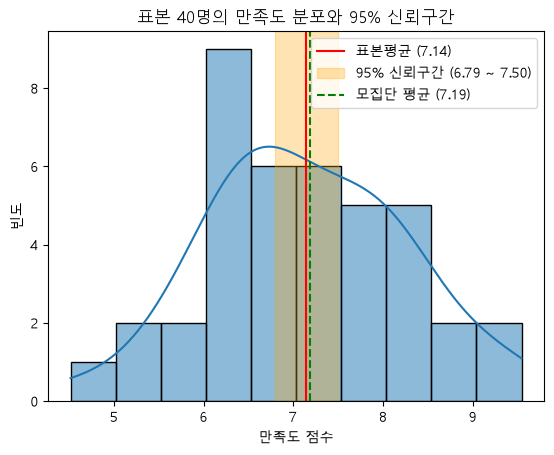

In [30]:
# [문제 5] Q3. 표본 데이터의 히스토그램을 그리고, 평균 및 신뢰구간을 함께 시각화해봅시다.
#  여기에 코드를 작성해주세요.

sns.histplot(sample, bins=10, kde=True)

plt.axvline(sample_mean, color='red', linestyle='-', label=f'표본평균 ({sample_mean:.2f})')
plt.axvspan(lower, upper, color='orange', alpha=0.3, label=f'95% 신뢰구간 ({lower:.2f} ~ {upper:.2f})')
plt.axvline(population.mean(), color='green', linestyle='--', label=f'모집단 평균 ({population.mean():.2f})')

plt.title("표본 40명의 만족도 분포와 95% 신뢰구간")
plt.xlabel("만족도 점수")
plt.ylabel("빈도")
plt.legend()
plt.show()

In [ ]:
# [문제 5] Q4. 신뢰구간의 결과에 따라 어떤 구체적인 마케팅 전략을 세울 수 있을까요?
# 여기에 의견을 작성해주세요.

표본 40명의 고객 만족도 평균과 95% 신뢰구간을 활용하여 전체 고객의 만족도 수준을 추정할 수 있습니다.
- 신뢰구간이 높은 만족도 영역에 있다면: 기존 서비스와 제품의 장점을 강조하는 마케팅을 진행하고, 만족도가 높은 고객의 긍정적인 리뷰와 추천을 활용할 수 있습니다.
- 신뢰구간이 예상보다 낮다면: 고객 불만의 원인을 조사하고, 서비스 품질이나 고객 응대 개선에 집중하는 전략을 세울 수 있습니다.
- 신뢰구간이 넓다면: 고객 만족도에 대한 불확실성이 크므로 추가 설문조사를 실시하여 더 많은 데이터를 확보할 수 있습니다.
이를 통해 고객 만족도 데이터를 바탕으로 마케팅 전략을 수립하고, 고객 경험 개선과 브랜드 신뢰도 향상을 도모할 수 있습니다.

**🧠 데이터를 어떻게 읽을까요?**

- 신뢰구간은 몇 점에서 몇 점 사이인가요?
> 6.79~7.50

- 이 구간은 전체 모집단 평균을 포함하고 있나요?
> 모집단 평균이 구간 안에 있다면 이번 신뢰구간은 모집단 평균을 포함하고 있다고 말할 수 있다. 

- 이 결과를 바탕으로 고객 만족도가 충분히 높다고 말할 수 있을까요?
> 신뢰구간이 높은 만족도 점수에 위치한다면 고객 만족도가 높다고 판단할 수 있는 근거가 된다. 하지만 만족도 기준을 먼저 정하고, 신뢰구간 전체가 그 기준을 넘는지 확인하는 것이 좋다.

- 만약 신뢰구간이 너무 넓게 나왔다면, 그 이유는 무엇이고 어떻게 개선할 수 있을까요?
> 표본 수가 적거나 고객 만족도 점수의 편차가 크기 때문에 신뢰구간이 넓어질 수 있다. 더 많은 고객을 대상으로 설문조사를 실시하고, 다양한 고객층의 의견을 수집하면 신뢰구간을 좁히는 데 도움이 된다.

In [ ]:
# [문제 5] 데이터를 어떻게 읽을까요?
# 여기에 의견을 작성해주세요.